<a href="https://colab.research.google.com/github/jimmyjcarranza/ribot-in-silico/blob/main/notebooks/02_ribot_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - The Ribot experiment

**Question:** when a language model is damaged little by little, does it forget first what it learned last?

This notebook runs the whole experiment from start to finish:

1. **The exam.** Find the facts the healthy model knows.
2. **The age of each memory.** Find when, during training, the model learned each of those facts.
3. **The damage.** Switch off random neurons in growing amounts and record which facts survive.
4. **The verdict.** Check whether facts learned early survive more damage than facts learned late, with a control for how confident the model was about each fact.

**How to run it:** in Colab, pick `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`. On a T4 it takes roughly 10 minutes. The last cell downloads a zip file with every table and figure.

Every number in the project README comes from the output of this notebook.

## 0. Setup

**What it does:** imports the libraries and sets every choice of the experiment in one place.

**What you should see:** `device: cuda` on a Colab GPU runtime, and the folder where results will be saved.

In [1]:
import json
import os
import shutil
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from scipy.stats import rankdata, spearmanr
from transformers import AutoModelForCausalLM, AutoTokenizer

# Every choice of the experiment lives here.
MODEL_NAME = "EleutherAI/pythia-160m"
FINAL_STEP = 143000
# Training snapshots used to date each fact, from untrained (0) to final.
STEPS = [0, 512, 1000, 2000, 4000, 8000, 16000, 32000, 48000,
         64000, 80000, 96000, 112000, 128000, 143000]
# Percent of MLP neurons switched off at each damage level.
DAMAGE_LEVELS = [0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 30]
N_SEEDS = 10          # independent random draws of which neurons are switched off
BATCH_SIZE = 128
RNG_SEED = 0          # for bootstraps, permutation tests and tie-breaking
COUNTERFACT_URL = "https://rome.baulab.info/data/dsets/counterfact.json"

device = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS = os.path.join("results", MODEL_NAME.split("/")[-1])
os.makedirs(RESULTS, exist_ok=True)
os.makedirs("data", exist_ok=True)
print("device:", device)
print("results folder:", RESULTS)

device: cuda
results folder: results/pythia-160m


## 1. The model and the scoring rule

**What it does:** loads the tokenizer and defines the two functions everything else uses.

- `load_checkpoint(step)` loads the snapshot of the model saved at a given training step.
- `score_facts(model, prompts, first_ids)` asks the model every prompt and returns, for each one, whether it got it right and how confident it was.

The rule is the one from notebook 01. A fact is **correct** when the first token of the right answer is the model's top prediction. **Confidence** is the probability the model gives to that token. **Margin** is how far the right token is ahead of its closest competitor, in raw score units.

**What you should see:** `(True, 0.511)` for the Hamlet fact, the same result as in notebook 01.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token   # the model has no padding token of its own
tokenizer.padding_side = "right"


def load_checkpoint(step):
    """Load the snapshot of the model saved at a given training step."""
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, revision=f"step{step}")
    # Weights are stored in float16. Cast to float32 so results match across machines.
    return model.float().to(device).eval()


def score_facts(model, prompts, first_ids):
    """Return (correct, confidence, margin) arrays, one entry per prompt."""
    correct, confidence, margin = [], [], []
    with torch.no_grad():
        for start in range(0, len(prompts), BATCH_SIZE):
            batch = prompts[start:start + BATCH_SIZE]
            enc = tokenizer(batch, return_tensors="pt", padding=True).to(device)
            hidden = model.gpt_neox(**enc).last_hidden_state
            # Position of the last real token of each prompt (prompts are padded on the right).
            last = enc.attention_mask.sum(dim=1) - 1
            rows = torch.arange(len(batch), device=device)
            # Turn only that last position into scores over the vocabulary.
            logits = model.get_output_embeddings()(hidden[rows, last])
            target = torch.tensor(first_ids[start:start + BATCH_SIZE], device=device)
            correct.append((logits.argmax(dim=-1) == target).cpu())
            confidence.append(torch.softmax(logits, dim=-1)[rows, target].cpu())
            # Margin: score of the right token minus the best score among all other tokens.
            target_score = logits[rows, target]
            others = logits.clone()
            others[rows, target] = float("-inf")
            margin.append((target_score - others.max(dim=-1).values).cpu())
    return torch.cat(correct).numpy(), torch.cat(confidence).numpy(), torch.cat(margin).numpy()


def first_token_id(answer):
    return tokenizer(answer).input_ids[0]


final_model = load_checkpoint(FINAL_STEP)
ok, conf, _ = score_facts(final_model, ["The author of Hamlet is William"], [first_token_id(" Shakespeare")])
print((bool(ok[0]), round(float(conf[0]), 3)))

# Self-check: the shortcut used in score_facts must match the model's own full output.
with torch.no_grad():
    enc = tokenizer("The author of Hamlet is William", return_tensors="pt").to(device)
    full = torch.softmax(final_model(**enc).logits[0, -1], dim=-1)[first_token_id(" Shakespeare")].item()
assert abs(full - float(conf[0])) < 1e-4, "score_facts does not match the model's full output."

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

(True, 0.511)


## 2. The exam

**What it does:** downloads CounterFact, a public list of about 22,000 simple facts, and asks all of them to the fully trained model. Only the facts the model gets right stay in the study: a fact the model never knew cannot be forgotten.

CounterFact comes from the ROME project (Meng et al., 2022). The file is downloaded from its original source and is not stored in this repository.

**What you should see:** the model knows only a small share of the facts, around 2 percent. That is expected for a model this small with a strict rule. The table shows which answers are most common among the known facts.

In [3]:
counterfact_path = os.path.join("data", "counterfact.json")
if not os.path.exists(counterfact_path):
    urllib.request.urlretrieve(COUNTERFACT_URL, counterfact_path)

with open(counterfact_path) as f:
    raw = json.load(f)

rows = []
for item in raw:
    rewrite = item["requested_rewrite"]
    rows.append({
        "case_id": item["case_id"],
        "relation": rewrite["relation_id"],
        "prompt": rewrite["prompt"].format(rewrite["subject"]),
        "answer": " " + rewrite["target_true"]["str"],
    })
exam = pd.DataFrame(rows).drop_duplicates(subset=["prompt", "answer"]).reset_index(drop=True)
exam["first_id"] = [first_token_id(a) for a in exam["answer"]]
print("facts in the exam:", len(exam))

facts in the exam: 21913


In [4]:
exam_path = os.path.join(RESULTS, "exam.csv")
if os.path.exists(exam_path):
    exam = pd.read_csv(exam_path)
    print("loaded saved exam results")
else:
    exam["correct"], exam["confidence"], exam["margin"] = score_facts(
        final_model, exam["prompt"].tolist(), exam["first_id"].tolist())
    exam.to_csv(exam_path, index=False)

known = exam[exam["correct"]].reset_index(drop=True)
print(f"known facts: {len(known)} of {len(exam)} ({len(known) / len(exam):.1%})")
print("confidence of known facts: median "
      f"{known['confidence'].median():.2f}, min {known['confidence'].min():.2f}, max {known['confidence'].max():.2f}")
print()
print("most common answers among known facts:")
print(known["answer"].value_counts().head(8).to_string())
assert len(known) >= 100, "Too few known facts to run the experiment."

known facts: 492 of 21913 (2.2%)
confidence of known facts: median 0.21, min 0.02, max 0.75

most common answers among known facts:
answer
Antarctica    63
French        56
Microsoft     49
Europe        26
London        26
Japan         25
Africa        21
Google        20


## 3. The age of each memory

**What it does:** gives the same exam to 15 snapshots of the model, from before training to the end. For each fact it records at which snapshots the model gets it right.

Two definitions of age are computed, because facts are not learned once and for all. A fact can be right at one snapshot, wrong at the next, and right again later.

- `age_first`: the first snapshot at which the model gets the fact right. This is the main definition.
- `age_stable`: the first snapshot from which the model gets it right at every later snapshot. This is reported as a robustness check only. A fact that keeps failing at some snapshots is a fragile fact, so `age_stable` partly measures fragility itself and would favor the hypothesis by construction.

**What you should see:** a table with the share of known facts answered correctly at each snapshot. It starts near 0 and ends at 1, and it does not rise smoothly. The cell also reports how many facts were lost and learned again at least once.

In [5]:
ages_path = os.path.join(RESULTS, "ages.csv")
prompts = known["prompt"].tolist()
first_ids = known["first_id"].tolist()

if os.path.exists(ages_path):
    ages = pd.read_csv(ages_path)
    print("loaded saved age results")
else:
    ages = known[["case_id"]].copy()
    for step in STEPS:
        model = final_model if step == FINAL_STEP else load_checkpoint(step)
        ages[f"correct_{step}"], ages[f"confidence_{step}"], _ = score_facts(model, prompts, first_ids)
        print(f"step {step:>6}: {ages[f'correct_{step}'].mean():.3f} of known facts correct")
        if step != FINAL_STEP:
            del model
    ages.to_csv(ages_path, index=False)

correct_by_step = ages[[f"correct_{s}" for s in STEPS]].to_numpy(dtype=bool)
assert correct_by_step[:, -1].all(), "Every known fact must be correct at the final step."

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

step      0: 0.000 of known facts correct


model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

... (46 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

step 128000: 0.811 of known facts correct
step 143000: 1.000 of known facts correct


In [6]:
steps_array = np.array(STEPS)

# age_first: first snapshot where the fact is correct.
age_first = steps_array[correct_by_step.argmax(axis=1)]

# age_stable: first snapshot from which the fact stays correct until the end.
# Walk backwards from the end and count how many snapshots in a row are correct.
run_from_end = np.cumprod(correct_by_step[:, ::-1], axis=1).sum(axis=1)
age_stable = steps_array[len(STEPS) - run_from_end]

# How many times each fact went from correct to wrong between two snapshots.
times_lost = (correct_by_step[:, :-1] & ~correct_by_step[:, 1:]).sum(axis=1)

known["age_first"] = age_first
known["age_stable"] = age_stable
known["times_lost"] = times_lost

learning_curve = pd.Series(correct_by_step.mean(axis=0), index=STEPS, name="share correct")
print(learning_curve.round(3).to_string())
print()
print(f"facts lost and learned again at least once: {(times_lost > 0).sum()} of {len(known)} "
      f"({(times_lost > 0).mean():.0%})")
print()
print("number of facts by age_first (training step):")
print(known["age_first"].value_counts().sort_index().to_string())

0         0.000
512       0.000
1000      0.008
2000      0.008
4000      0.132
8000      0.264
16000     0.394
32000     0.549
48000     0.516
64000     0.679
80000     0.537
96000     0.774
112000    0.707
128000    0.811
143000    1.000

facts lost and learned again at least once: 339 of 492 (69%)

number of facts by age_first (training step):
age_first
1000       4
2000       4
4000      62
8000      82
16000     96
32000     96
48000     30
64000     47
80000     10
96000     30
112000     9
128000    12
143000    10


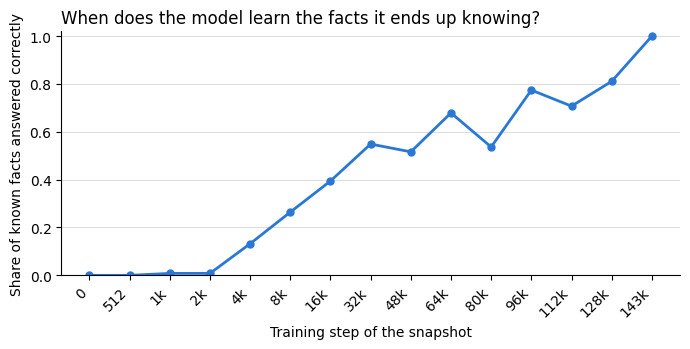

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(STEPS))
ax.plot(x, learning_curve.values, color="#2a78d6", linewidth=2, marker="o", markersize=5)
ax.set_xticks(x)
ax.set_xticklabels([f"{s // 1000}k" if s >= 1000 else str(s) for s in STEPS], rotation=45, ha="right")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Training step of the snapshot")
ax.set_ylabel("Share of known facts answered correctly")
ax.set_title("When does the model learn the facts it ends up knowing?", loc="left")
ax.grid(axis="y", color="#dddddd", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS, "fig_learning_curve.png"), dpi=150)
plt.show()

## 4. The damage

**What it does:** switches off random neurons of the fully trained model and gives it the exam again.

- A neuron is switched off by forcing its output to zero. The neurons are the hidden units of the MLP block of each layer.
- Damage grows in levels, from 0.5 to 30 percent of all neurons. Levels are nested: the neurons switched off at one level stay off at the next.
- The whole sequence is repeated with 10 different random draws, so the result does not depend on the luck of a single draw.

For each fact, **resistance** is the share of all damage trials (10 draws times 10 levels) in which the model still gets it right. A second measure, `levels_survived`, counts how many levels in a row the fact survives before its first failure.

**What you should see:** a table with one row per random draw and one column per damage level. The share of facts still correct falls as damage grows. It does not always fall steadily: some facts fail at one level and come back at a higher one.

In [8]:
layers = final_model.gpt_neox.layers
n_layers = len(layers)
n_neurons = final_model.config.intermediate_size
total_neurons = n_layers * n_neurons
print(f"{n_layers} layers x {n_neurons} neurons = {total_neurons} MLP neurons")

# One row of ones and zeros per layer. A zero switches that neuron off.
neuron_mask = torch.ones(n_layers, n_neurons, device=device)


def make_hook(layer_index):
    # Runs just before the second half of the MLP and multiplies the neuron outputs by the mask.
    def hook(module, inputs):
        return (inputs[0] * neuron_mask[layer_index],)
    return hook


hooks = [layer.mlp.dense_4h_to_h.register_forward_pre_hook(make_hook(i)) for i, layer in enumerate(layers)]

# Sanity check: with every neuron on, the model must still know every known fact.
check, _, _ = score_facts(final_model, prompts, first_ids)
assert check.all(), "The hooks changed the healthy model."
print("healthy model with hooks installed: all known facts correct")

12 layers x 3072 neurons = 36864 MLP neurons
healthy model with hooks installed: all known facts correct


In [9]:
damage_path = os.path.join(RESULTS, "damage.npz")
expected_shape = (N_SEEDS, len(DAMAGE_LEVELS), len(known))

alive = None
if os.path.exists(damage_path):
    saved = np.load(damage_path)["alive"]
    if saved.shape == expected_shape:
        alive = saved
        print("loaded saved damage results")

if alive is None:
    # alive[draw, level, fact] is True when the fact is still correct.
    alive = np.zeros(expected_shape, dtype=bool)
    for seed in range(N_SEEDS):
        generator = torch.Generator().manual_seed(seed)
        order = torch.randperm(total_neurons, generator=generator)   # random order of all neurons
        for j, level in enumerate(DAMAGE_LEVELS):
            n_off = int(round(total_neurons * level / 100))
            flat = torch.ones(total_neurons)
            flat[order[:n_off]] = 0          # nested: a higher level switches off a longer prefix
            neuron_mask.copy_(flat.view(n_layers, n_neurons))
            alive[seed, j], _, _ = score_facts(final_model, prompts, first_ids)
        print(f"draw {seed + 1} of {N_SEEDS} done")
    np.savez_compressed(damage_path, alive=alive)

neuron_mask.fill_(1)
for h in hooks:
    h.remove()

survival_table = pd.DataFrame(alive.mean(axis=2), columns=[f"{lv}%" for lv in DAMAGE_LEVELS],
                              index=[f"draw {s + 1}" for s in range(N_SEEDS)])
print()
print("share of known facts still correct, by random draw and damage level:")
print(survival_table.round(2).to_string())

# Resistance of each fact: share of all trials it survives.
known["resistance"] = alive.mean(axis=(0, 1))
# Levels in a row survived before the first failure, averaged over draws.
known["levels_survived"] = np.cumprod(alive, axis=1).sum(axis=1).mean(axis=0)
came_back = ((~alive[:, :-1, :]) & alive[:, 1:, :]).any(axis=1).mean()
print()
print(f"share of (fact, draw) pairs where a fact failed and came back at a higher level: {came_back:.0%}")

draw 1 of 10 done
draw 2 of 10 done
draw 3 of 10 done
draw 4 of 10 done
draw 5 of 10 done
draw 6 of 10 done
draw 7 of 10 done
draw 8 of 10 done
draw 9 of 10 done
draw 10 of 10 done

share of known facts still correct, by random draw and damage level:
         0.5%    1%    2%    3%    5%  7.5%   10%   15%   20%   30%
draw 1   0.93  0.89  0.76  0.66  0.53  0.61  0.49  0.34  0.27  0.14
draw 2   0.95  0.87  0.78  0.68  0.55  0.50  0.57  0.40  0.24  0.06
draw 3   0.93  0.86  0.83  0.68  0.59  0.35  0.30  0.20  0.02  0.01
draw 4   0.94  0.85  0.82  0.79  0.51  0.43  0.43  0.20  0.20  0.18
draw 5   0.92  0.93  0.86  0.75  0.73  0.64  0.54  0.40  0.22  0.13
draw 6   0.95  0.90  0.74  0.60  0.58  0.54  0.49  0.25  0.22  0.13
draw 7   0.95  0.91  0.83  0.82  0.74  0.70  0.64  0.40  0.23  0.09
draw 8   0.89  0.90  0.89  0.77  0.58  0.30  0.26  0.22  0.18  0.10
draw 9   0.95  0.88  0.76  0.73  0.65  0.45  0.51  0.29  0.09  0.07
draw 10  0.92  0.89  0.86  0.57  0.51  0.39  0.33  0.26  0.12  0.05



## 5. The verdict

**What it does:** crosses the age of each fact with its resistance.

If the model behaved like Ribot's law, facts learned **earlier** (smaller `age_first`) would be **more** resistant. That shows up as a **negative** correlation between age and resistance.

There is a trap. Facts learned early also tend to be facts the model holds more firmly, and a firmly held fact can resist damage for that reason alone. So the correlation is computed three times:

1. **Raw:** age against resistance.
2. **Controlled for confidence:** after removing what confidence explains in both. This is a partial rank correlation.
3. **Controlled for confidence and margin:** the strictest version. The conclusion of the notebook is based on this one.

The same three numbers are repeated as robustness checks: with the stricter definition of age, with at most 10 facts per answer so that a few very common answers do not drive the result, and with the other resistance measure.

**What you should see:** a table with one row per analysis. Read the `rho` column: negative means early facts resist more. Read `p` as the chance of seeing a value this far from zero if age did not matter.

In [10]:
rng = np.random.default_rng(RNG_SEED)


def spearman_with_ci(x, y, n_boot=2000):
    """Rank correlation with a bootstrap 95% interval."""
    x, y = np.asarray(x), np.asarray(y)
    rho, p = spearmanr(x, y)
    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        boot.append(spearmanr(x[idx], y[idx])[0])
    low, high = np.nanpercentile(boot, [2.5, 97.5])
    return rho, p, low, high


def remove_effect(values, controls):
    """Rank everything and remove from `values` what the control variables explain linearly."""
    ranked = rankdata(values)
    design = np.column_stack([np.ones(len(ranked))] + [rankdata(c) for c in controls])
    coefficients, *_ = np.linalg.lstsq(design, ranked, rcond=None)
    return ranked - design @ coefficients


def partial_spearman(x, y, controls, n_perm=5000):
    """Rank correlation of x and y after removing the controls from both, with a permutation p-value."""
    rx, ry = remove_effect(x, controls), remove_effect(y, controls)
    rho = np.corrcoef(rx, ry)[0, 1]
    shuffled = np.array([np.corrcoef(rng.permutation(rx), ry)[0, 1] for _ in range(n_perm)])
    p = (np.sum(np.abs(shuffled) >= abs(rho)) + 1) / (n_perm + 1)
    return rho, p


def analyse(table, age_column, label, outcome="resistance"):
    """Three rows: raw, controlled for confidence, controlled for confidence and margin."""
    rho, p, low, high = spearman_with_ci(table[age_column], table[outcome])
    rho_c, p_c = partial_spearman(table[age_column], table[outcome], [table["confidence"]])
    rho_cm, p_cm = partial_spearman(table[age_column], table[outcome], [table["confidence"], table["margin"]])
    return [
        {"analysis": f"{label}: raw", "n": len(table), "rho": rho, "p": p, "ci_low": low, "ci_high": high},
        {"analysis": f"{label}: controlled for confidence", "n": len(table), "rho": rho_c, "p": p_c},
        {"analysis": f"{label}: controlled for confidence and margin", "n": len(table), "rho": rho_cm, "p": p_cm},
    ]


# Main analysis.
main_raw, main_confidence, main_strict = analyse(known, "age_first", "age_first")

# Robustness: the stricter definition of age.
stable_rows = analyse(known, "age_stable", "age_stable")

# Robustness: at most 10 facts per answer, chosen at random.
capped = known.sample(frac=1, random_state=RNG_SEED).groupby("answer").head(10)
capped_rows = analyse(capped, "age_first", "age_first, max 10 facts per answer")
capped_strict = capped_rows[2]

# Robustness: the other resistance measure, levels survived before the first failure.
levels_rows = analyse(known, "age_first", "age_first vs levels_survived", outcome="levels_survived")

results = [main_raw, main_confidence, main_strict] + stable_rows + capped_rows + levels_rows
verdict = pd.DataFrame(results)
print(verdict.round(4).to_string(index=False))

# The confound, measured.
rho_age_conf = spearmanr(known["age_first"], known["confidence"])[0]
rho_conf_res = spearmanr(known["confidence"], known["resistance"])[0]
rho_margin_res = spearmanr(known["margin"], known["resistance"])[0]
print()
print(f"age_first vs confidence:   rho = {rho_age_conf:+.3f}  (negative: early facts are more confident)")
print(f"confidence vs resistance:  rho = {rho_conf_res:+.3f}  (positive: confident facts resist more)")
print(f"margin vs resistance:      rho = {rho_margin_res:+.3f}  (positive: facts with a wide margin resist more)")

                                                                analysis   n     rho      p  ci_low  ci_high
                                                          age_first: raw 492 -0.2992 0.0000 -0.3822  -0.2065
                                    age_first: controlled for confidence 492 -0.2294 0.0002     NaN      NaN
                         age_first: controlled for confidence and margin 492 -0.1516 0.0004     NaN      NaN
                                                         age_stable: raw 492 -0.5329 0.0000 -0.5987  -0.4608
                                   age_stable: controlled for confidence 492 -0.4360 0.0002     NaN      NaN
                        age_stable: controlled for confidence and margin 492 -0.2239 0.0002     NaN      NaN
                                 age_first, max 10 facts per answer: raw 265 -0.2427 0.0001 -0.3662  -0.1171
           age_first, max 10 facts per answer: controlled for confidence 265 -0.1860 0.0022     NaN      NaN
age_first, max 10 f

### The same question inside groups of similar confidence

**What it does:** splits the facts into five groups by confidence and computes the correlation of age with resistance inside each group. Inside a group, confidence is roughly the same for every fact, so it cannot explain a difference.

**What you should see:** five rows. If age matters beyond confidence, `rho` should be negative in most groups.

In [11]:
known["confidence_group"] = pd.qcut(known["confidence"], 5, labels=False, duplicates="drop")
group_rows = []
for group, part in known.groupby("confidence_group"):
    rho, p = spearmanr(part["age_first"], part["resistance"])
    group_rows.append({
        "confidence group": int(group) + 1,
        "n": len(part),
        "confidence range": f"{part['confidence'].min():.2f} to {part['confidence'].max():.2f}",
        "rho": rho,
        "p": p,
    })
by_group = pd.DataFrame(group_rows)
print(by_group.round(3).to_string(index=False))

 confidence group  n confidence range    rho     p
                1 99     0.02 to 0.11 -0.182 0.072
                2 98     0.11 to 0.17 -0.135 0.184
                3 98     0.18 to 0.25 -0.312 0.002
                4 98     0.25 to 0.37 -0.203 0.045
                5 99     0.37 to 0.75 -0.178 0.079


### Figure 1: survival by cohort

**What it does:** splits the known facts into three cohorts by `age_first` (early, middle, late) and plots, for each cohort, the share of facts still correct at each damage level. The shaded band is the spread across the 10 random draws.

**What you should see:** three falling curves. If the early cohort stays above the late one, early facts resist more. This figure does not control for confidence. Figure 2 does.

facts per cohort:
        count    min     max
cohort                      
early     248   1000   16000
middle     96  32000   32000
late      148  48000  143000


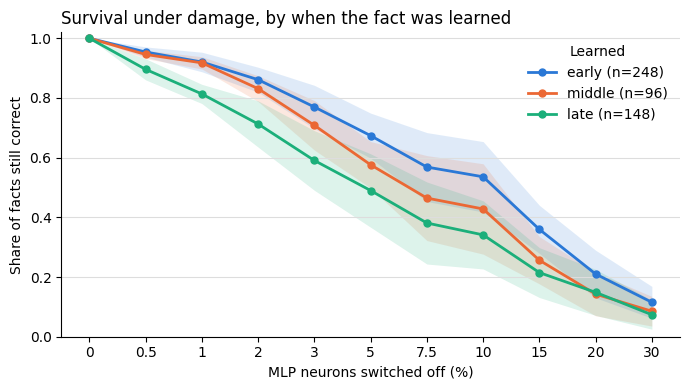

In [12]:
COLORS = {"early": "#2a78d6", "middle": "#eb6834", "late": "#1baf7a"}

cut_low, cut_high = known["age_first"].quantile([1 / 3, 2 / 3])
known["cohort"] = np.where(known["age_first"] <= cut_low, "early",
                           np.where(known["age_first"] <= cut_high, "middle", "late"))
print("facts per cohort:")
print(known.groupby("cohort")["age_first"].agg(["count", "min", "max"]).reindex(["early", "middle", "late"]).to_string())


def survival_curves(labels, names):
    """Mean and spread across draws of the share alive, for each group, starting at zero damage."""
    curves = {}
    for name in names:
        members = (labels == name).to_numpy()
        per_draw = alive[:, :, members].mean(axis=2)                 # [draw, level]
        per_draw = np.concatenate([np.ones((N_SEEDS, 1)), per_draw], axis=1)
        curves[name] = (per_draw.mean(axis=0), per_draw.std(axis=0), int(members.sum()))
    return curves


def plot_survival(curves, title, path):
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(DAMAGE_LEVELS) + 1)
    for name, (mean, spread, n) in curves.items():
        ax.fill_between(x, mean - spread, mean + spread, color=COLORS[name], alpha=0.15, linewidth=0)
        ax.plot(x, mean, color=COLORS[name], linewidth=2, marker="o", markersize=5, label=f"{name} (n={n})")
    ax.set_xticks(x)
    ax.set_xticklabels(["0"] + [f"{lv:g}" for lv in DAMAGE_LEVELS])
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("MLP neurons switched off (%)")
    ax.set_ylabel("Share of facts still correct")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="#dddddd", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, title="Learned")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


present = [name for name in ["early", "middle", "late"] if (known["cohort"] == name).any()]
cohort_curves = survival_curves(known["cohort"], present)
plot_survival(cohort_curves, "Survival under damage, by when the fact was learned",
              os.path.join(RESULTS, "fig_survival_by_cohort.png"))

### Figure 2: survival with confidence matched

**What it does:** inside each of the five confidence groups, the facts are split in half by age: the earlier half and the later half. The halves are then pooled across groups. Both pooled sets have almost the same confidence by construction, so a gap between the two curves cannot come from confidence.

A permutation test asks how often a gap this large appears when the early and late labels are shuffled inside each confidence group.

**What you should see:** two curves and a short summary. If the gap of Figure 1 shrinks or disappears here, confidence was explaining it.

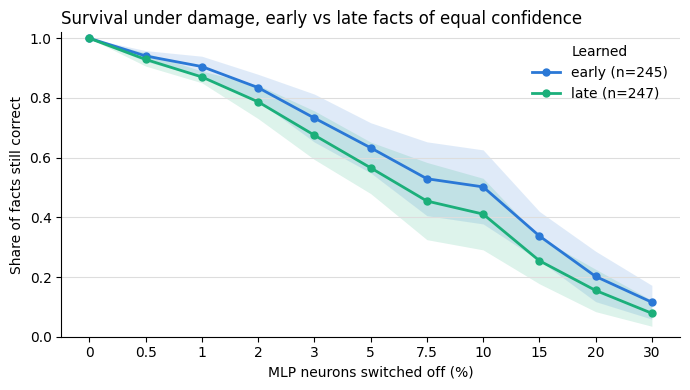

                n  mean_confidence  median_age_first  mean_resistance
matched_half                                                         
early         245            0.246            8000.0            0.573
late          247            0.239           48000.0            0.518

gap in resistance, early minus late, confidence matched: +0.055 (permutation p = 0.0010)


In [13]:
known["tiebreak"] = rng.random(len(known))
known["matched_half"] = "late"
for group, part in known.groupby("confidence_group"):
    ordered = part.sort_values(["age_first", "tiebreak"]).index
    known.loc[ordered[: len(ordered) // 2], "matched_half"] = "early"

matched_curves = survival_curves(known["matched_half"], ["early", "late"])
plot_survival(matched_curves, "Survival under damage, early vs late facts of equal confidence",
              os.path.join(RESULTS, "fig_survival_matched.png"))

summary_matched = known.groupby("matched_half").agg(
    n=("resistance", "size"),
    mean_confidence=("confidence", "mean"),
    median_age_first=("age_first", "median"),
    mean_resistance=("resistance", "mean"),
).reindex(["early", "late"])
print(summary_matched.round(3).to_string())


def matched_gap(labels):
    is_early = (labels == "early").to_numpy()
    return known["resistance"].to_numpy()[is_early].mean() - known["resistance"].to_numpy()[~is_early].mean()


observed_gap = matched_gap(known["matched_half"])
shuffled_gaps = []
groups = [part.index.to_numpy() for _, part in known.groupby("confidence_group")]
labels_array = known["matched_half"].to_numpy()
resistance_array = known["resistance"].to_numpy()
position = {idx: i for i, idx in enumerate(known.index)}
group_positions = [np.array([position[i] for i in g]) for g in groups]
for _ in range(5000):
    shuffled = labels_array.copy()
    for pos in group_positions:
        shuffled[pos] = rng.permutation(labels_array[pos])
    early = shuffled == "early"
    shuffled_gaps.append(resistance_array[early].mean() - resistance_array[~early].mean())
matched_p = (np.sum(np.abs(shuffled_gaps) >= abs(observed_gap)) + 1) / (len(shuffled_gaps) + 1)
print()
print(f"gap in resistance, early minus late, confidence matched: {observed_gap:+.3f} (permutation p = {matched_p:.4f})")

## 6. The result in one paragraph

**What it does:** writes the result as text, using only the numbers computed above, and saves every table. The wording follows fixed rules written in the cell, so the conclusion does not depend on anyone's judgment after seeing the numbers.

**What you should see:** a block of text ready to paste into the README.

In [14]:
ALPHA = 0.05


def early_resist_more(row):
    return row["p"] < ALPHA and row["rho"] < 0


def late_resist_more(row):
    return row["p"] < ALPHA and row["rho"] > 0


# Two robustness checks that the main result has to pass to count as solid.
checks = {
    "at most 10 facts per answer": early_resist_more(capped_strict),
    "confidence-matched halves": matched_p < ALPHA and observed_gap > 0,
}
failed = [name for name, passed in checks.items() if not passed]

if early_resist_more(main_strict) and not failed:
    conclusion = ("Facts learned earlier survive more damage. The effect remains after controlling for confidence "
                  "and margin, and it holds in both robustness checks. This is consistent with a Ribot-like "
                  "gradient in this model.")
elif early_resist_more(main_strict):
    conclusion = ("Facts learned earlier survive more damage, and the effect remains after controlling for "
                  "confidence and margin. It is small and it does not hold in every robustness check "
                  f"(not significant with: {', '.join(failed)}). The evidence for a Ribot-like gradient in this "
                  "model is weak.")
elif early_resist_more(main_raw):
    conclusion = ("Facts learned earlier survive more damage, but the effect does not remain after controlling "
                  "for confidence and margin. In this model the gradient is explained by how firmly the model "
                  "held each fact, not by when the fact was learned.")
elif late_resist_more(main_strict):
    conclusion = ("After controlling for confidence and margin, facts learned later survive more damage. "
                  "This is the opposite of a Ribot-like gradient.")
else:
    conclusion = ("No reliable relationship was found between when a fact was learned and how much damage it "
                  "survives. This is a null result for a Ribot-like gradient in this model.")

lines = [
    f"Model: {MODEL_NAME}. Facts in the exam: {len(exam)}. Known by the final model: {len(known)} "
    f"({len(known) / len(exam):.1%}).",
    f"Snapshots used to date each fact: {len(STEPS)}. Facts lost and learned again at least once during "
    f"training: {(known['times_lost'] > 0).mean():.0%}.",
    f"Damage: {len(DAMAGE_LEVELS)} nested levels from {DAMAGE_LEVELS[0]}% to {DAMAGE_LEVELS[-1]}% of "
    f"{total_neurons} MLP neurons, {N_SEEDS} random draws.",
    f"Age vs resistance (Spearman): rho = {main_raw['rho']:+.3f}, 95% CI [{main_raw['ci_low']:+.3f}, "
    f"{main_raw['ci_high']:+.3f}], p = {main_raw['p']:.2g}.",
    f"Controlled for confidence (partial Spearman): rho = {main_confidence['rho']:+.3f}, "
    f"p = {main_confidence['p']:.2g}.",
    f"Controlled for confidence and margin: rho = {main_strict['rho']:+.3f}, p = {main_strict['p']:.2g}.",
    f"Same, with at most 10 facts per answer (n = {capped_strict['n']}): rho = {capped_strict['rho']:+.3f}, "
    f"p = {capped_strict['p']:.2g}.",
    f"Confidence-matched gap in resistance, early minus late: {observed_gap:+.3f}, p = {matched_p:.2g}.",
    f"The confound: age vs confidence rho = {rho_age_conf:+.3f}; confidence vs resistance rho = {rho_conf_res:+.3f}; "
    f"margin vs resistance rho = {rho_margin_res:+.3f}.",
    conclusion,
]
result_text = "\n".join("- " + line for line in lines)
print(result_text)

known.drop(columns=["tiebreak"]).to_csv(os.path.join(RESULTS, "facts.csv"), index=False)
verdict.to_csv(os.path.join(RESULTS, "verdict.csv"), index=False)
by_group.to_csv(os.path.join(RESULTS, "verdict_by_confidence_group.csv"), index=False)
survival_table.to_csv(os.path.join(RESULTS, "survival_by_draw.csv"))
with open(os.path.join(RESULTS, "result.md"), "w") as f:
    f.write(result_text + "\n")
with open(os.path.join(RESULTS, "run_info.json"), "w") as f:
    json.dump({
        "model": MODEL_NAME, "steps": STEPS, "damage_levels": DAMAGE_LEVELS, "n_seeds": N_SEEDS,
        "device": device, "gpu": torch.cuda.get_device_name(0) if device == "cuda" else None,
        "torch": torch.__version__, "transformers": transformers.__version__,
    }, f, indent=2)
print()
print("saved to", RESULTS, ":", sorted(os.listdir(RESULTS)))

- Model: EleutherAI/pythia-160m. Facts in the exam: 21913. Known by the final model: 492 (2.2%).
- Snapshots used to date each fact: 15. Facts lost and learned again at least once during training: 69%.
- Damage: 10 nested levels from 0.5% to 30% of 36864 MLP neurons, 10 random draws.
- Age vs resistance (Spearman): rho = -0.299, 95% CI [-0.382, -0.207], p = 1.2e-11.
- Controlled for confidence (partial Spearman): rho = -0.229, p = 0.0002.
- Controlled for confidence and margin: rho = -0.152, p = 0.0004.
- Same, with at most 10 facts per answer (n = 265): rho = -0.090, p = 0.14.
- Confidence-matched gap in resistance, early minus late: +0.055, p = 0.001.
- The confound: age vs confidence rho = -0.234; confidence vs resistance rho = +0.408; margin vs resistance rho = +0.714.
- Facts learned earlier survive more damage, and the effect remains after controlling for confidence and margin. It is small and it does not hold in every robustness check (not significant with: at most 10 facts per 

## 7. Download the results

**What it does:** packs the results folder into one zip file and, in Colab, downloads it to your computer.

**What you should see:** a file named `results.zip` in your downloads. Upload its contents to the `results` folder of the repository.

In [15]:
shutil.make_archive("results", "zip", root_dir=".", base_dir="results")
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("Not running in Colab. The file results.zip is in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Checkpoint: explain it in your own words

Answer these without looking at the code:

1. Why does the study keep only the facts the final model gets right?
2. What is the difference between `age_first` and `age_stable`, and why are there two?
3. What does it mean that damage levels are nested, and why is the damage repeated with 10 random draws?
4. What is the confound, and how do the controlled correlations and Figure 2 deal with it?
5. If the raw correlation is negative and the controlled one is not, what is the honest conclusion?